In [31]:
import os
import sys
import pandas as pd
import numpy as np
import time
import umap
import matplotlib.pyplot as plt
import umap
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.helper_functions import load_outlier_data
from utils.plotting import plot_movement_data_3d
from utils.constants import Configs
from utils.plotting import plot_dimesionality_reduction_outliers

# Define the target movement for anomaly detection
TARGET_MOVEMENT = 'Park'

In [32]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if os.path.exists(cache_path):
    print(f"Loading processed data from {cache_path}")
    df = pd.read_csv(cache_path)
else:
    print(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

Loading processed data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/data/processed/filtered_data_bimanual.csv


In [33]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


### Discard sub 13.
Aparently his movements were not good at all. The existance of those movements might influence the detection of other outliers 

In [34]:
# Discard from dataset
df.drop(df[df['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [35]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = [
    'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
    'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 180/180 [00:00<00:00, 7229.55it/s]

Shape of first series: (46, 18)
Shape of formatted series: (180, 466, 18)


In [36]:
# =========================================================================
# A BASE DE CÁLCULO 
# =========================================================================

# Extrair os metadados diretamente da fonte da verdade
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

# --- Parâmetros Dinâmicos (Limites de Lixo) ---
total_trials = len(results_temp_base)
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100


if total_trials != X_movement.shape[0]:
    print(f"⚠️ ERRO CRÍTICO: Metadados ({total_trials}) não batem com Matriz ({X_movement.shape[0]})!")
else:
    print(f"✅ Sincronização Perfeita! Linhas na Matriz: {X_movement.shape[0]} | Linhas nos Metadados: {total_trials}")

✅ Sincronização Perfeita! Linhas na Matriz: 180 | Linhas nos Metadados: 180


## UMAP

In [37]:
print(f"\n--- A preparar dados para UMAP Bimanual ({TARGET_MOVEMENT}) ---")

# Extrair TODAS as 18 coordenadas
X_all = X_movement.copy() 
n_samples, n_timepoints, n_dims = X_all.shape  # n_dims será automaticamente 18

# LIMPEZA DE NaNs (Forward Fill - Obrigatório para PCA)
for i in range(n_samples):
    for j in range(n_dims):
        s = pd.Series(X_all[i, :, j])
        X_all[i, :, j] = s.ffill().bfill().values

# Concatenação (Esmagar de 3D para 2D)
# Passamos para uma matriz plana de (n_samples, n_timepoints * 18)
X_flat = np.transpose(X_all, (0, 2, 1)).reshape(n_samples, n_timepoints * n_dims)


--- A preparar dados para UMAP Bimanual (Park) ---


In [38]:
# UMAP hyperparameters range for Grid Search
min_n_components = 3
max_n_components = 10 
umap_neighbors_options = [5, 15] 

# Parâmetros LOF
min_contam = 0.01
max_contam = known_outlier_rate + 0.15        
contamination_range = [round(c, 3) for c in np.linspace(min_contam, max_contam, 15)]
lof_neighbors_options = [3, 5, 7, 10, 15, 20] 

results_log = []

print("\n--- Iniciando Grid Search Dinâmico (UMAP + LOF) ---")

for u_neigh in umap_neighbors_options:
    for n_comp in range(min_n_components, max_n_components + 1):
        
        # TREINO DO UMAP
        umap_start_time = time.perf_counter()
        reducer = umap.UMAP(n_neighbors=u_neigh, n_components=n_comp, random_state=42)
        umap_scores = reducer.fit_transform(X_flat)
        umap_end_time = time.perf_counter()

        for l_neigh in lof_neighbors_options:
            for contam in contamination_range:
                lof_start_time = time.perf_counter()

                # TREINO DO LOF (nos scores não-lineares do UMAP)
                model = LocalOutlierFactor(n_neighbors=l_neigh, contamination=contam, metric='minkowski')
                labels = model.fit_predict(umap_scores)
                lof_end_time = time.perf_counter()
            
                # --- CÁLCULO DE MÉTRICAS ---
                results_temp = results_temp_base.copy()
                results_temp['label'] = labels
                
                real_outliers_info = results_temp[results_temp['label'] == -1]
                identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
                
                matched_outliers = pd.merge(identified_unique, outliers_bimanual, on=['sub', 'repID'], how='inner')
                missing_outliers = pd.merge(outliers_bimanual, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
                missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']
                
                TP = len(matched_outliers)
                FP = len(identified_unique) - TP
                FN = len(missing_outliers)
                
                if (TP + FP) > 0:
                    precision = (TP / (TP + FP)) * 100
                    recall = (TP / total_known_outliers) * 100
                    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                    f2_score = (5 * precision * recall) / (4 * precision + recall) if (precision + recall) > 0 else 0
                else:
                    precision, recall, f1_score, f2_score = 0.0, 0.0, 0.0, 0.0
                    
                percentagem_lixo = (len(identified_unique) / total_trials) * 100
                    
                results_log.append({
                    'umap_neighbors': u_neigh,
                    'n_components': n_comp,
                    'lof_neighbors': l_neigh,
                    'contamination': contam,
                    'total_time': (umap_end_time - umap_start_time) + (lof_end_time - lof_start_time),
                    'Recall': recall,
                    'Precision': precision,
                    'F1-Score': f1_score,
                    'F2-Score': f2_score,
                    'TP': TP,
                    'FP': FP,
                    'FN': FN,
                    'Percentagem Lixo': percentagem_lixo
                })


--- Iniciando Grid Search Dinâmico (UMAP + LOF) ---


/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHu

In [39]:
# --- SELEÇÃO DO MELHOR MODELO ---
results_df = pd.DataFrame(results_log)
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    print(f"⚠️ Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo. A usar todos.")
    acceptable_models = results_df

best_results = acceptable_models.sort_values(by=['F2-Score', 'Percentagem Lixo'], ascending=[False, True])
best_params = best_results.iloc[0]

percentagem_lixo = best_params['Percentagem Lixo']
retencao = 100 - best_params['Percentagem Lixo']
print(f"--- Grid Search (UMAP + LOF): ---")
print(f"UMAP Neighbors: {best_params['umap_neighbors']} | Components: {best_params['n_components']}")
print(f"LOF Neighbors: {best_params['lof_neighbors']} | Contamination: {best_params['contamination']}")
print(f"Precision: {best_params['Precision']:.2f}% | Recall: {best_params['Recall']:.2f}%")
print(f"F1-Score: {best_params['F1-Score']:.2f}% | F2-Score: {best_params['F2-Score']:.2f}%")
print(f"Retencao: {retencao:.2f}% | Lixo: {percentagem_lixo:.2f}%")
print(f"TP: {best_params['TP']} | FP: {best_params['FP']} | FN: {best_params['FN']}")
print(f"Total Time: {best_params['total_time']:.4f} segundos")

--- Grid Search (UMAP + LOF): ---
UMAP Neighbors: 5.0 | Components: 10.0
LOF Neighbors: 3.0 | Contamination: 0.225
Precision: 33.33% | Recall: 41.67%
F1-Score: 37.04% | F2-Score: 39.68%
Retencao: 83.33% | Lixo: 16.67%
TP: 10.0 | FP: 20.0 | FN: 12.0
Total Time: 0.1229 segundos


In [40]:
print("\n--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS (VENCEDOR UMAP) ---")

# Restore the best parameters
best_u_neigh = int(best_params['umap_neighbors'])
best_n_comp = int(best_params['n_components'])
best_l_neigh = int(best_params['lof_neighbors'])
best_contam = best_params['contamination']

# Re-train
reducer_final = umap.UMAP(n_neighbors=best_u_neigh, n_components=best_n_comp, random_state=42)
umap_scores_final = reducer_final.fit_transform(X_flat)

model_final = LocalOutlierFactor(n_neighbors=best_l_neigh, contamination=best_contam, metric='minkowski')
final_labels = model_final.fit_predict(umap_scores_final)

outlier_indices = np.where(final_labels == -1)[0]
inlier_indices = np.where(final_labels == 1)[0]

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Total de Repetições Analisadas: {len(X_movement)}")
print(f"Outliers Bimanuais Detetados: {len(outlier_indices)}")


--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS (VENCEDOR UMAP) ---
Total de Repetições Analisadas: 180
Outliers Bimanuais Detetados: 41


/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Plot UMAP

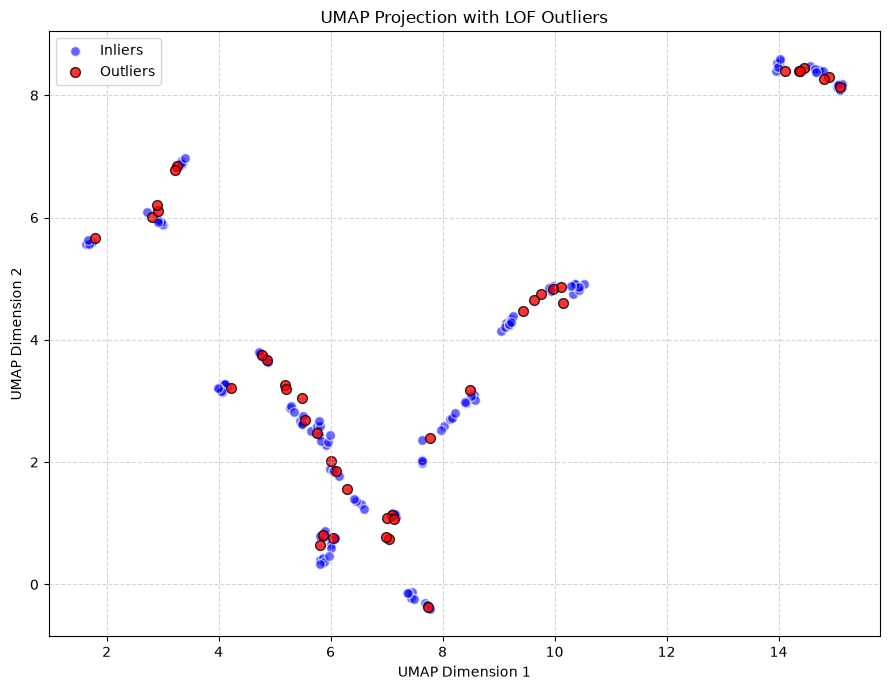

In [41]:
plot_dimesionality_reduction_outliers(umap_scores_final, outlier_indices, inlier_indices, "UMAP", "LOF")

In [42]:
print("\n--- IDENTIDADE DOS OUTLIERS DETETADOS ---")

outliers_identificados = results_temp_base.iloc[outlier_indices].copy()

print(f"Encontrados {len(outliers_identificados)} outliers bimanuais:")
print(outliers_identificados[['sub', 'repID', 'movID']].to_string(index=False))


--- IDENTIDADE DOS OUTLIERS DETETADOS ---
Encontrados 41 outliers bimanuais:
 sub  repID  movID
   1      1      9
   1      2      9
   1      4      9
   2      3      9
   4      5      9
   5      5      9
   6      1      9
   6      4      9
   7      4      9
   7      5      9
  10      1      9
  10      4      9
  10      5      9
  11      3      9
  12      1      9
  12      1     11
  12      1     12
  12      4      9
  12      5      9
  12      5     10
  12      5     11
  12      5     12
  14      4      9
  15      1     10
  15      2     10
  16      2      9
  16      2     12
  16      3     12
  17      2      9
  17      2     12
  17      3      9
  17      5     10
  18      1     10
  18      4     11
  18      4     12
  18      5     11
  18      5     12
  19      1     10
  19      1     11
  19      1     12
  19      5     10


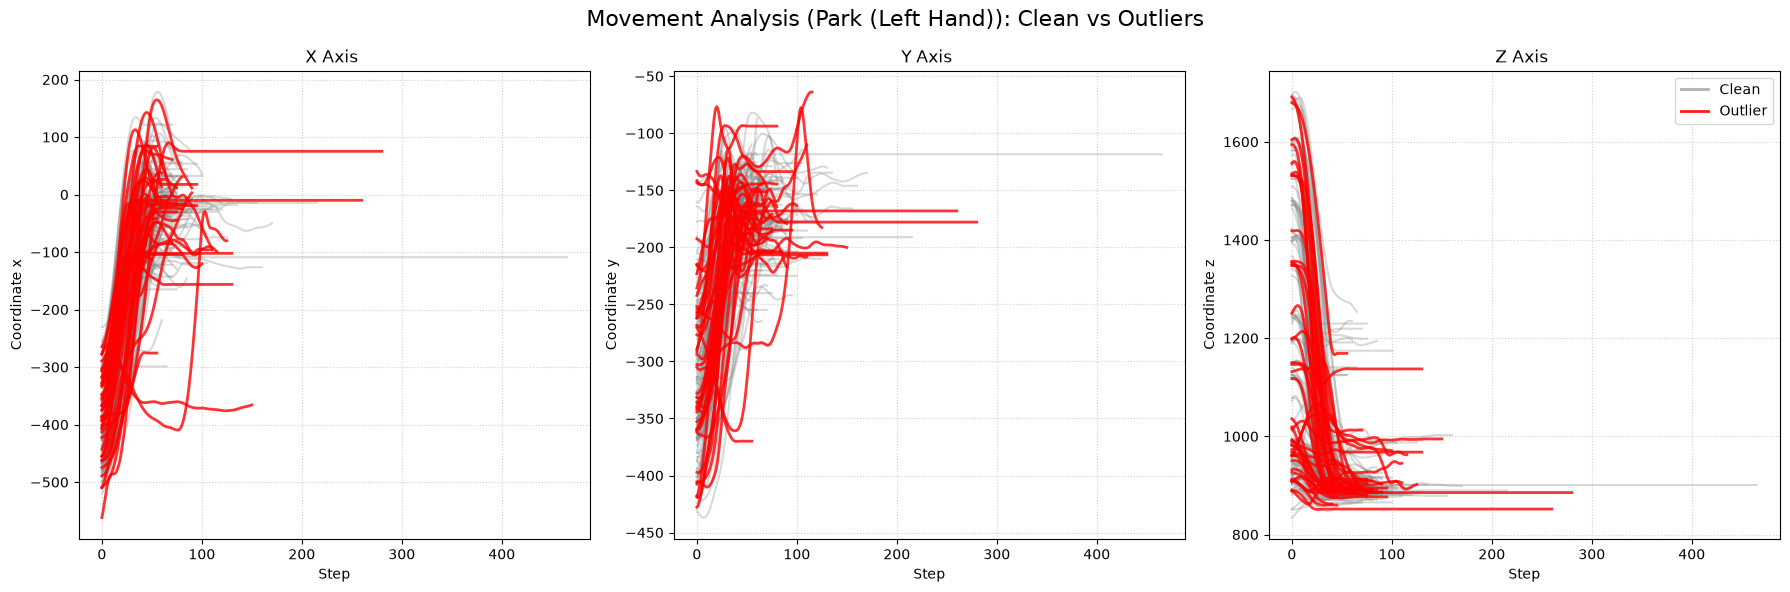

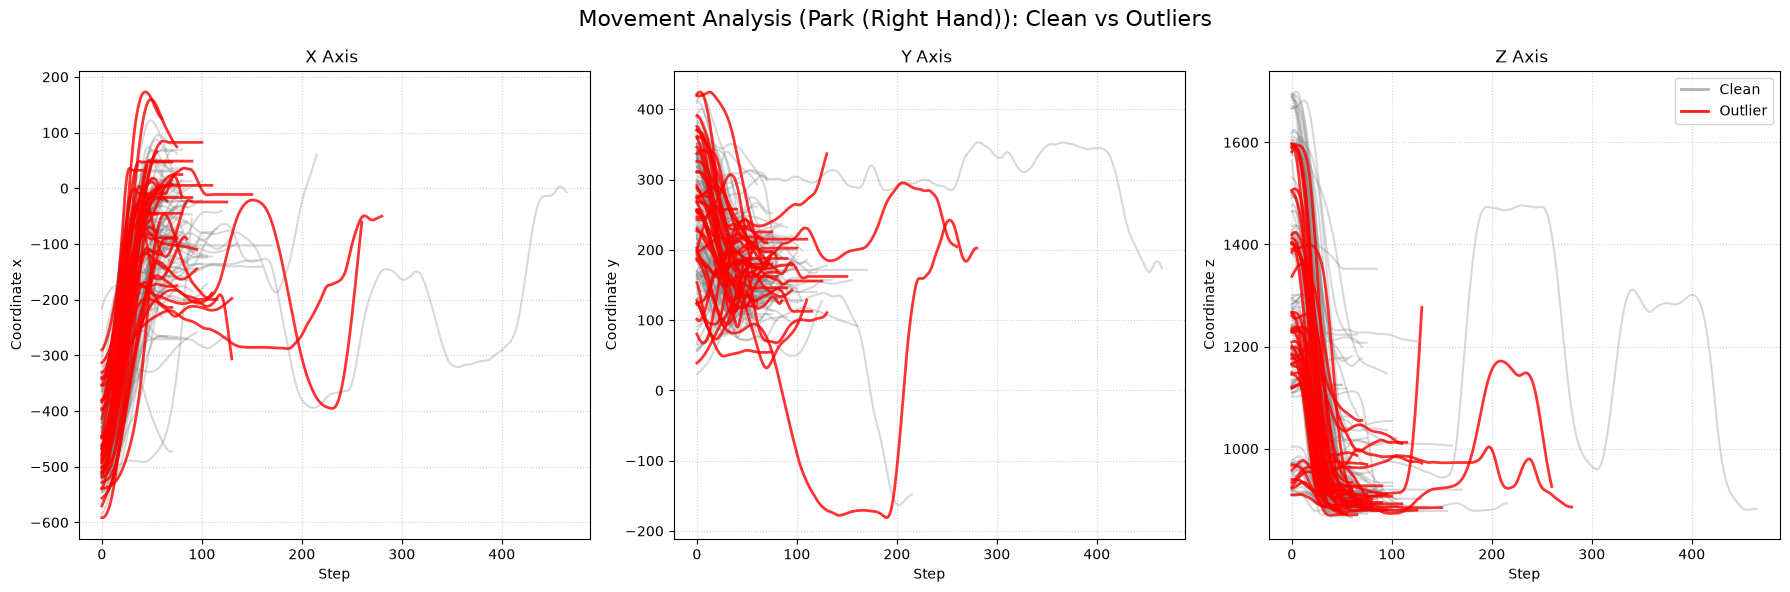

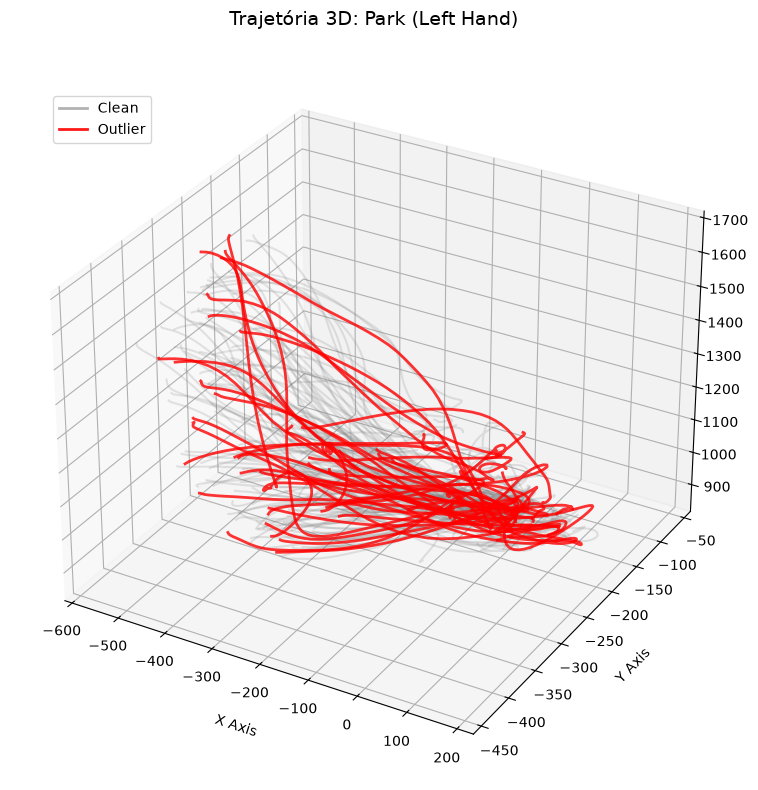

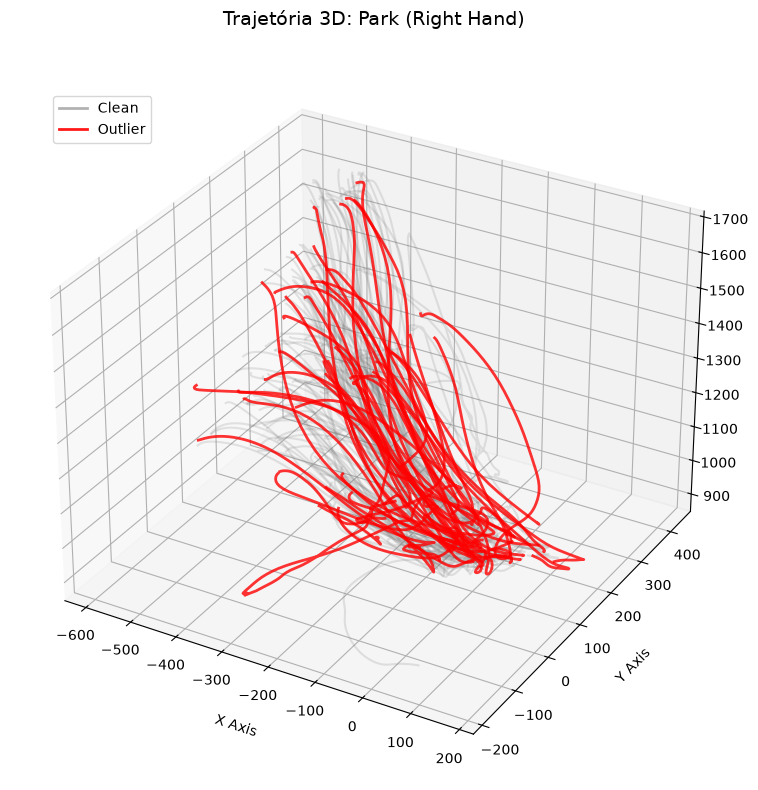

In [43]:
plot_movement_data(
    clean_data=X_movement_clean[:, :, 6:9],       
    outlier_data=X_movement_outliers[:, :, 6:9],  
    target_movement=f"{TARGET_MOVEMENT} (Left Hand)"
)

plot_movement_data(
    clean_data=X_movement_clean[:, :, 15:18],       
    outlier_data=X_movement_outliers[:, :, 15:18],  
    target_movement=f"{TARGET_MOVEMENT} (Right Hand)"
)

# 

plot_movement_data_3d(
    clean_data=X_movement_clean[:, :, 6:9],       
    outlier_data=X_movement_outliers[:, :, 6:9],  
    target_movement=f"{TARGET_MOVEMENT} (Left Hand)"
)
plot_movement_data_3d(
    clean_data=X_movement_clean[:, :, 15:18],       
    outlier_data=X_movement_outliers[:, :, 15:18],  
    target_movement=f"{TARGET_MOVEMENT} (Right Hand)"
)


In [44]:
# Atualizar também a variável real_outliers_info para o meu script de passar a faca
results_temp = results_temp_base.copy()
results_temp['label'] = final_labels
real_outliers_info = results_temp[results_temp['label'] == -1].copy()

### Exportar Inliers

In [45]:
# ---------------------------------------------------------
# Limpar e isolar APENAS o movimento pretendido
# ---------------------------------------------------------

df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()
outliers_keys = real_outliers_info[['sub', 'repID', 'movID']].copy()

# 2. Fazer um merge (Anti-Join) do dataframe FILTRADO com a lista de outliers do PCA
# O indicator=True cria uma coluna chamada '_merge' que nos diz de onde veio a linha
df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID'], how='left', indicator=True)

# Manter APENAS as linhas que estão limpas ('left_only')
df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])


print(f"--- RESUMO DA LIMPEZA ({TARGET_MOVEMENT}) ---")
print(f"Linhas do movimento {TARGET_MOVEMENT} antes da limpeza: {len(df_target_only)}")
print(f"Linhas removidas (pertencentes a outliers): {len(df_target_only) - len(df_cleaned)}")
print(f"Linhas do movimento {TARGET_MOVEMENT} limpas: {len(df_cleaned)}")

# Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
n_removidos_esperados = len(outliers_keys)
print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
print(f"Movimentos originais eram {total_trials}, removemos {n_removidos_esperados}, batem certo? {len(movimentos_restantes) == (total_trials - n_removidos_esperados)}")

save_dir = str(Configs.movement_inliers_umap_path(TARGET_MOVEMENT))
df_cleaned.to_csv(save_dir, index=False)

print(f"\n✅ Inliers do {TARGET_MOVEMENT} (via UMAP) guardados com sucesso em: {save_dir}")

--- RESUMO DA LIMPEZA (Park) ---
Linhas do movimento Park antes da limpeza: 14980
Linhas removidas (pertencentes a outliers): 3631
Linhas do movimento Park limpas: 11349

Movimentos 'Park' que SOBRARAM: 139
Movimentos originais eram 180, removemos 41, batem certo? True

✅ Inliers do Park (via UMAP) guardados com sucesso em: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_UMAP/data/processed/df_cleaned_inliers_Park_only.csv
